# Long-only MLFactor strategy

This is the graded analysis notebook. The assignment prompt stays in `03_mlfactor_long_only_project.ipynb`. Each section is a short comment and a function call. The functions live in `research/notebook_views.py` and only read saved studies.

Annual log growth sits beside CAGR. Annual log growth is 12 times the mean monthly portfolio log return, log(1 + r). CAGR is the exponential of that growth, minus 1. Volatility, Sharpe, and max drawdown are on the same rows. Sharpe uses the simple returns.

The books come from `STORY`, `DISPLAY_MODEL`, and `CHOICE`. The four factory classifiers are logistic regression, Gaussian naive Bayes, random forest, and histogram gradient boosting. K nearest neighbors is an additional model type in the categorizing section. Nothing here fits a model or opens the stock files.


In [1]:
# Read-only. Find the project even if the kernel starts in this notebook's folder.
import os
import sys
from pathlib import Path

os.environ["MLFACTOR_READ_ONLY"] = "1"
here = Path.cwd().resolve()
for candidate in (here, *here.parents):
    if (candidate / "research" / "notebook_views.py").is_file():
        sys.path.insert(0, str(candidate))
        break


## Equal-weight log growth and CAGR

Training is January 2000–December 2009. The official test is January 2010–December 2018. Combined compounds those monthly simple returns through December 2018. The graded annualized return is the official-test CAGR. The same rows carry annual log growth, volatility, Sharpe, and max drawdown.


In [2]:
# Independent equal-weight files. Annual log growth is 12 * mean(log(1 + r)). CAGR is exp(that) - 1. Combined compounds training months, then test months.
from research.notebook_views import equal_weight_benchmark, equal_weight_sentence, source_note, style_table

print(source_note("benchmark"))
display(style_table(equal_weight_benchmark()))
print(equal_weight_sentence())


Independent equal-weight files. Training is January 2000–December 2009, 120 months. The official test is January 2010–December 2018, 108 months. Combined compounds those monthly simple returns, January 2000–December 2018. Annual log growth is 12 * mean(log(1 + r)). CAGR is exp(that) - 1.


Period,Months,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown
Training,120,13.54%,14.50%,19.92%,0.783,-49.51%
Official test,108,12.31%,13.10%,15.63%,0.868,-20.64%
Combined,228,12.95%,13.83%,17.98%,0.814,-49.51%


The graded equal-weight figure is the official-test CAGR, 13.096%, over 108 months. Annual log growth on that same path is 12.307%. The combined path, January 2000 through December 2018, has annual log growth 12.955% and CAGR 13.831%.


## Two non-ML books

Equal weight is the benchmark. The second book is positive-volatility momentum. Full baskets are the other constructed book. Each window shows annual log growth, CAGR, volatility, Sharpe, and max drawdown. The training window is January 2005–December 2009. The official test is January 2010–December 2018. The combined path compounds those strategy months, January 2005–December 2018. The chart is the official test. Gross of costs. Cash earns nothing.


Newest final-book save final_20261110T025420_6d3405bd: 2010-01-31 through 2018-12-31, frozen_at_origin at 2009-12-31. Training window 2005-01-31 through 2009-12-31.


Window,Book,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown,Average cash
Training window · Jan 2005–Dec 2009,Equal weight,7.34%,7.62%,23.19%,0.433,-49.51%,0.00%
Training window · Jan 2005–Dec 2009,Top 10 positive-vol,22.06%,24.68%,31.67%,0.833,-20.55%,50.43%
Training window · Jan 2005–Dec 2009,Full baskets,9.59%,10.07%,15.00%,0.709,-13.95%,57.80%
Official test · Jan 2010–Dec 2018,Equal weight,12.31%,13.10%,15.63%,0.868,-20.64%,0.00%
Official test · Jan 2010–Dec 2018,Top 10 positive-vol,17.91%,19.61%,39.20%,0.591,-21.33%,51.56%
Official test · Jan 2010–Dec 2018,Full baskets,3.93%,4.01%,8.07%,0.528,-12.37%,54.18%
Combined path · Jan 2005–Dec 2018,Equal weight,10.53%,11.11%,18.62%,0.661,-49.51%,0.00%
Combined path · Jan 2005–Dec 2018,Top 10 positive-vol,19.39%,21.40%,36.60%,0.664,-21.33%,51.15%
Combined path · Jan 2005–Dec 2018,Full baskets,5.95%,6.14%,11.04%,0.592,-13.95%,55.47%


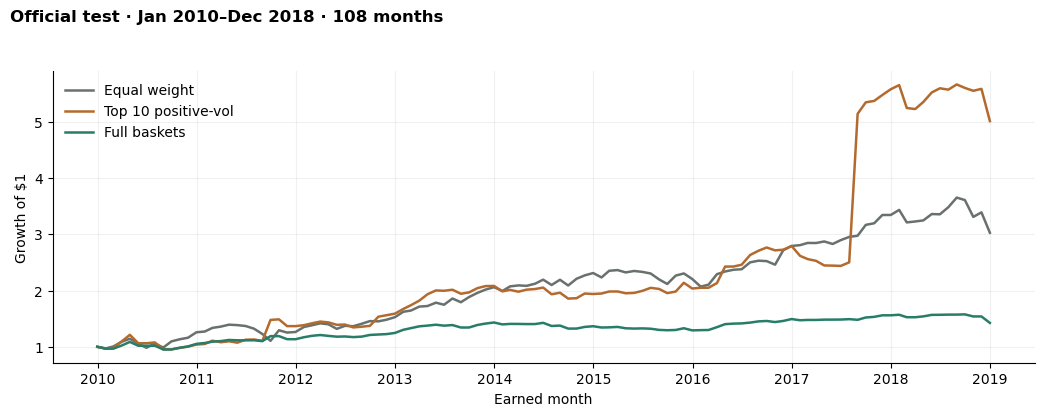

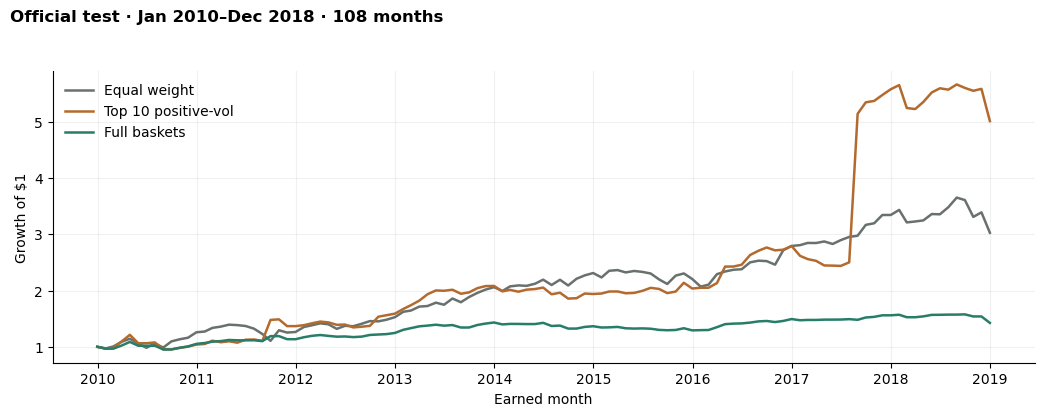

In [3]:
# Newest final-book save. Non-ML books on the training window, the official test, and the combined path. The chart is the official test.
from research.notebook_views import non_ml_figure, non_ml_windows_table, source_note, style_table

print(source_note("final"))
display(style_table(non_ml_windows_table()))
display(non_ml_figure("test"))


## Four model types

Logistic regression, Gaussian naive Bayes, random forest, and histogram gradient boosting. Logistic regression, the forest, and histogram gradient boosting have tunable hyperparameters. Gaussian naive Bayes is the fourth family. Each overlay book is one row per model. The columns are annual log growth, CAGR, volatility, Sharpe, and max drawdown. The windows are the training window, the official test, and the combined strategy path. These saved books use factory settings.


In [4]:
# Newest final-book save. All four factory classifiers, on every saved window. Annual log growth, CAGR, volatility, Sharpe, and max drawdown.
from research.notebook_views import classifier_growth_table, source_note, style_table

print(source_note("final"))
growth = classifier_growth_table()
for window, part in growth.groupby("Window", sort=False):
    print(window)
    display(style_table(part.drop(columns=["Window"])))


Newest final-book save final_20261110T025420_6d3405bd: 2010-01-31 through 2018-12-31, frozen_at_origin at 2009-12-31. Training window 2005-01-31 through 2009-12-31.


Training window · Jan 2005–Dec 2009


Book,Model,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown
Equal weight,No ML,7.34%,7.62%,23.19%,0.433,-49.51%
Top 10 positive-vol,No ML,22.06%,24.68%,31.67%,0.833,-20.55%
Top 10 + downside to cash,Logistic regression,17.74%,19.41%,24.51%,0.833,-16.12%
Top 10 + downside to cash,Gaussian naive Bayes,17.82%,19.51%,24.25%,0.843,-15.83%
Top 10 + downside to cash,Random forest,17.42%,19.03%,23.82%,0.838,-16.00%
Top 10 + downside to cash,Histogram gradient boosting,17.31%,18.90%,23.73%,0.836,-16.01%
Top 10 + upside tilt,Logistic regression,22.29%,24.98%,31.63%,0.841,-20.57%
Top 10 + upside tilt,Gaussian naive Bayes,22.36%,25.06%,30.71%,0.861,-19.34%
Top 10 + upside tilt,Random forest,22.05%,24.67%,31.66%,0.833,-20.55%
Top 10 + upside tilt,Histogram gradient boosting,22.09%,24.72%,31.67%,0.834,-20.55%


Official test · Jan 2010–Dec 2018


Book,Model,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown
Equal weight,No ML,12.31%,13.10%,15.63%,0.868,-20.64%
Top 10 positive-vol,No ML,17.91%,19.61%,39.20%,0.591,-21.33%
Top 10 + downside to cash,Logistic regression,14.53%,15.64%,30.36%,0.590,-16.65%
Top 10 + downside to cash,Gaussian naive Bayes,14.32%,15.40%,29.84%,0.589,-16.29%
Top 10 + downside to cash,Random forest,14.53%,15.64%,30.45%,0.588,-16.45%
Top 10 + downside to cash,Histogram gradient boosting,14.70%,15.83%,31.21%,0.583,-16.46%
Top 10 + upside tilt,Logistic regression,17.91%,19.61%,39.20%,0.591,-21.33%
Top 10 + upside tilt,Gaussian naive Bayes,17.99%,19.71%,39.14%,0.593,-20.97%
Top 10 + upside tilt,Random forest,17.90%,19.60%,39.20%,0.590,-21.33%
Top 10 + upside tilt,Histogram gradient boosting,20.17%,22.35%,53.77%,0.528,-21.33%


Combined path · Jan 2005–Dec 2018


Book,Model,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown
Equal weight,No ML,10.53%,11.11%,18.62%,0.661,-49.51%
Top 10 positive-vol,No ML,19.39%,21.40%,36.60%,0.664,-21.33%
Top 10 + downside to cash,Logistic regression,15.68%,16.97%,28.33%,0.664,-16.65%
Top 10 + downside to cash,Gaussian naive Bayes,15.57%,16.85%,27.90%,0.667,-16.29%
Top 10 + downside to cash,Random forest,15.56%,16.84%,28.19%,0.661,-16.45%
Top 10 + downside to cash,Histogram gradient boosting,15.63%,16.92%,28.69%,0.655,-16.46%
Top 10 + upside tilt,Logistic regression,19.48%,21.50%,36.58%,0.667,-21.33%
Top 10 + upside tilt,Gaussian naive Bayes,19.55%,21.59%,36.27%,0.672,-20.97%
Top 10 + upside tilt,Random forest,19.38%,21.39%,36.59%,0.664,-21.33%
Top 10 + upside tilt,Histogram gradient boosting,20.86%,23.19%,46.97%,0.589,-21.33%


## Categorizing with K nearest neighbors

K nearest neighbors, from the textbook classifier, and multinomial logistic regression. Both use sklearn `GridSearchCV`. The category is the within-month quintile of the next-month simple return. The search uses labels known by December 2006. The holdout is January 2007–December 2009, still inside the training file. K nearest neighbors is one of the model types. The frozen 2010–2018 books above keep the four factory classifiers. The basket book groups by K-means on return paths. This model groups by the predicted return quintile.


In [5]:
# Newest grouping study. Training file only. GridSearchCV for K nearest neighbors and logistic regression. The book is the training holdout.
from research.notebook_views import (
    grouping_book_table,
    grouping_class_table,
    grouping_note,
    grouping_search_table,
    source_note,
    style_table,
)

print(source_note("grouping"))
search = grouping_search_table()
classes = grouping_class_table()
display(search.style.format({"Best score": "{:.4f}"}, na_rep="—").hide(axis="index"))
display(classes.style.format({
    "Holdout accuracy": "{:.1%}",
    "Chance accuracy": "{:.1%}",
    "Holdout log loss": "{:.3f}",
    "Uniform log loss": "{:.3f}",
}, na_rep="—").hide(axis="index"))
display(style_table(grouping_book_table()))
print(grouping_note())


Newest grouping study grouping_20261110T044153_b86c80c0: search labels through 2006-12-31, holdout earned returns 2007-01-31 through 2009-12-31. GridSearchCV score neg_log_loss. Training file only.


Model,Searched,Chosen,Fits,Best score
K nearest neighbors,"n_neighbors: 5, 15, 31, 51",n_neighbors=51,13,-1.6239
Logistic regression,"C: 0.1, 1, 10",C=0.1,10,-1.5797


Model,Holdout accuracy,Chance accuracy,Holdout log loss,Uniform log loss
K nearest neighbors,22.6%,20.0%,1.663,1.609
Logistic regression,22.7%,20.0%,1.605,1.609


Book,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown
Equal weight,2.59%,2.62%,28.48%,0.231,-49.51%
"K nearest neighbors, top category",7.05%,7.30%,34.74%,0.371,-54.26%
"Logistic regression, top category",6.78%,7.01%,33.33%,0.364,-52.06%


K nearest neighbors is one of the model types. GridSearchCV chose n_neighbors=51 for K nearest neighbors and C=0.1 for multinomial logistic regression, using labels through 2006-12-31 and the neg_log_loss score. On the January 2007–December 2009 training holdout, K nearest neighbors accuracy is 22.6% against a chance accuracy of 20.0%. Its holdout log loss is 1.663, and logistic regression holdout log loss is 1.605, against a uniform-guess log loss of 1.609. Its top-category book has annual log growth 7.05% and CAGR 7.30%, against equal weight at 2.59% and 2.62%. This search did not open the official test file. It is not inside the frozen 2010–2018 books, which still use the four factory classifiers. The basket book groups by K-means on return paths; this model groups by the predicted return quintile.


## Did a ten-factor cut change the book?

Feature choice is judged on the training window, before the official test. The question is whether a subset of at most ten factors changes the book versus all twenty factors. Recipe names come from the save (ANOVA, correlation pruning, forest importance). The name list under the table is the frozen official-test fit, which can differ from those training-window recipes.


In [6]:
# Newest feature-score save, training years only. Overlay books at DISPLAY_MODEL. Did a ten-factor cut move CAGR versus all 20 factors?
from research.notebook_views import feature_cut_table, feature_name_note, source_note

print(source_note("features"))
cuts = feature_cut_table()
display(cuts.style.format({column: "{:.2%}" for column in cuts.columns if column != "Book"}, na_rep="—").hide(axis="index"))
print(feature_name_note())


Newest feature-score save features_20261110T022741_e6f5661f: 2005-01-31 through 2009-12-31. This window is the training years.


Book,All 20 original factors,ANOVA top 10,Correlation-pruned up to 10 (|r| < 0.90),Random forest top 10,Largest gap vs all 20
Top 10 + downside to cash,19.41%,19.42%,19.40%,19.47%,0.06%
Top 10 + upside tilt,24.98%,24.78%,24.86%,24.78%,-0.20%
Baskets + downside to cash,7.92%,7.91%,7.91%,7.93%,0.01%
Baskets + upside tilt,10.01%,9.98%,10.00%,9.98%,-0.04%


Inside the frozen fit, 10 names were chosen for Logistic regression, and loss and upside use the same list: Tot_Debt_Rev, Net_Debt, Share_Turn_3M, Debtequity, Ocf_Ce, Div_Yld, Share_Turn_12M, Tev_Less_Mktcap, Total_Debt_Capital, Share_Turn_6M. On the training years recorded by the newest feature-score study (2005-01-31 through 2009-12-31, 60 months), not the official test, the largest absolute CAGR gap versus all 20 for Logistic regression is 0.20 percentage points below all 20, on Top 10 + upside tilt under Random forest top 10; the cut does not meaningfully change the book, and it satisfies a ten-or-fewer feature limit.


## What GridSearchCV searched

The search uses sklearn `GridSearchCV` on training data only. The score is a probability score, log loss, not portfolio return. The holdout is the saved training cut, currently January 2007–December 2009. The question is whether the searched settings change the book. The official-test books above were not refit with these settings.


In [7]:
# Newest saved GridSearchCV holdout. Training years only. Search table, then whether the holdout book moved. Not the official test.
from research.notebook_views import source_note, tuning_note, tuning_portfolio_table, tuning_search_table

print(source_note("tuning"))
search = tuning_search_table()
books = tuning_portfolio_table()
display(search.style.format({"Best score": "{:.4f}"}, na_rep="—").hide(axis="index"))
percent = {column: "{:.2%}" for column in books.columns if column not in {"Strategy", "Model"}}
display(books.style.format(percent, na_rep="—").hide(axis="index"))
print(tuning_note())


Newest GridSearchCV holdout holdout_20261110T013013_6f2fd4f9: earned returns 2007-01-31 through 2009-12-31. Search score neg_log_loss. Prediction target upside.


Model,Searched,Chosen,Fits,Best score
Logistic regression,"C: 0.1, 1, 10",C: 0.1,10,-0.6817
Gaussian naive Bayes,"var_smoothing: 1e-09, 1e-05",var_smoothing: 1e-05,7,-0.6950
Random forest,"max_depth: 4, 6; min_samples_leaf: 50, 200",max_depth: 4; min_samples_leaf: 200,13,-0.6809
Histogram gradient boosting,"learning_rate: 0.05, 0.1; max_leaf_nodes: 15, 31",learning_rate: 0.05; max_leaf_nodes: 15,13,-0.6818


Strategy,Model,No ML CAGR,Untuned CAGR,Tuned CAGR,Tuned minus untuned
Equal-weight universe,Logistic regression,2.62%,2.30%,2.30%,0.00%
Equal-weight universe,Gaussian naive Bayes,2.62%,2.03%,2.03%,0.00%
Equal-weight universe,Random forest,2.62%,2.47%,2.48%,0.01%
Equal-weight universe,Histogram gradient boosting,2.62%,2.46%,2.46%,0.00%
Training Sortino pool + momentum,Logistic regression,-5.31%,-4.81%,-4.81%,0.00%
Training Sortino pool + momentum,Gaussian naive Bayes,-5.31%,-5.59%,-5.59%,0.00%
Training Sortino pool + momentum,Random forest,-5.31%,-4.96%,-4.76%,0.20%
Training Sortino pool + momentum,Histogram gradient boosting,-5.31%,-4.93%,-4.93%,0.00%
"High volatility, equal weight",Logistic regression,20.41%,20.17%,20.17%,0.01%
"High volatility, equal weight",Gaussian naive Bayes,20.41%,21.17%,21.17%,0.00%


GridSearchCV searched the January 2007–December 2009 training holdout with the neg_log_loss score and the upside prediction target. The largest absolute tuned-minus-untuned CAGR on the equal-weight holdout book is 0.01%, so the portfolio barely moved. These holdout rows are registry rules on the training cut; the official 2010–2018 books in the other cells use factory classifier settings, so this search is not the model inside that test.


## Risk and reward

Annual log growth, CAGR, volatility, Sharpe, and max drawdown are on the same rows. The windows are the official test, the training window, and the path that compounds the training months and then the test months. The line on the chart is the first official-test month. Gross of costs. Cash earns nothing.


Window,Book,Annual log growth,CAGR,Volatility,Sharpe,Max drawdown,Average cash
Official test,Equal weight,12.31%,13.10%,15.63%,0.868,-20.64%,0.00%
Official test,Top 10 positive-vol,17.91%,19.61%,39.20%,0.591,-21.33%,51.56%
Official test,Top 10 + downside to cash,14.53%,15.64%,30.36%,0.590,-16.65%,62.75%
Official test,Top 10 + upside tilt,17.91%,19.61%,39.20%,0.591,-21.33%,51.56%
Official test,Full baskets,3.93%,4.01%,8.07%,0.528,-12.37%,54.18%
Official test,Baskets + downside to cash,3.10%,3.15%,6.25%,0.527,-9.67%,64.40%
Official test,Baskets + upside tilt,3.93%,4.01%,8.07%,0.528,-12.36%,54.18%
Training window,Equal weight,7.34%,7.62%,23.19%,0.433,-49.51%,0.00%
Training window,Top 10 positive-vol,22.06%,24.68%,31.67%,0.833,-20.55%,50.43%
Training window,Top 10 + downside to cash,17.74%,19.41%,24.51%,0.833,-16.12%,61.82%


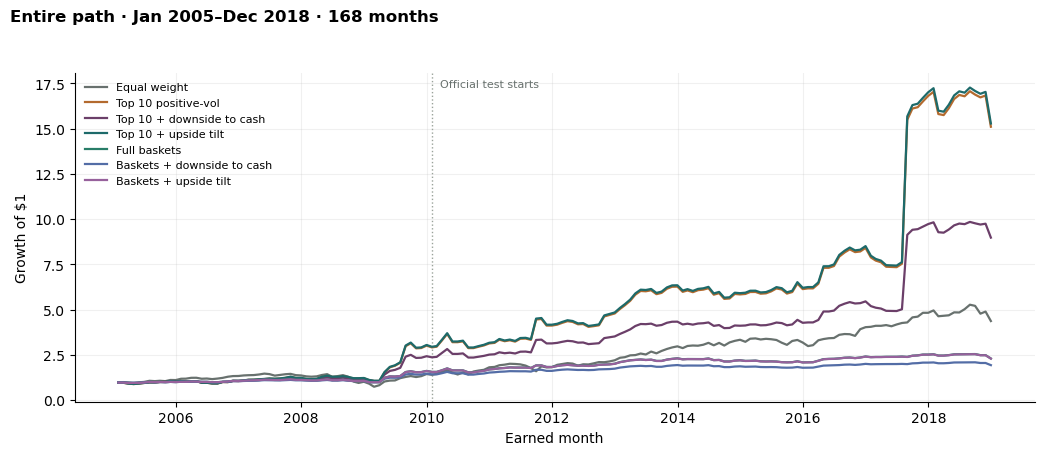

Official test is January 2010 through December 2018, the training window is January 2005 through December 2009, and the entire path is January 2005 through December 2018, compounding the training months and then the test months. On the official test, Top 10 positive-vol CAGR is 19.61% and Sharpe is 0.591, against Equal weight at 13.10% and 0.868. Equal weight's max drawdown on the entire path is -49.51%, larger than the official-test drawdown of -20.64%, because that deeper drop comes from the training window; training-window overlay rows are the saved training forecasts, while official-test rows are the one frozen fit.


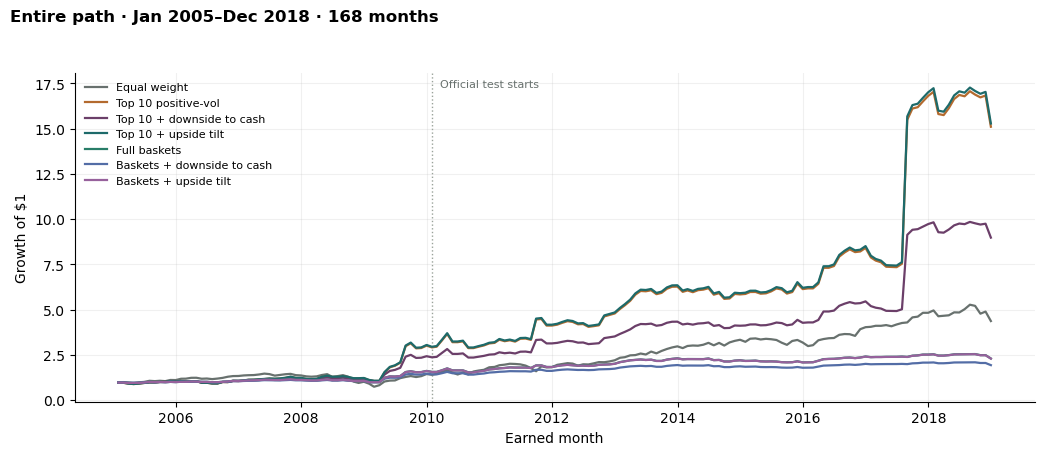

In [8]:
# Three windows from the newest final-book save and the saved training months. No new fit. The chart compounds training into the test when both exist.
from research.notebook_views import path_figure, risk_note, risk_table, style_table

display(style_table(risk_table()))
display(path_figure())
print(risk_note())


## The book I would trade

The choice is the book named in `CHOICE`, judged on the official test. Annual log growth and CAGR are stated beside the Sharpe. The paragraph is read from the newest save, so the numbers move if that save is replaced.


In [9]:
# Official test of the declared choice. Numbers come from the newest final-book save. Factory settings. The disclosure sentence is fixed.
from research.notebook_views import choice_text

print(choice_text())


The book I would trade is Top 10 positive-vol, with an official-test annual log growth of 17.9%, CAGR of 19.6%, volatility of 39.2%, a Sharpe of 0.591, and a max drawdown of -21.3%, against equal weight at annual log growth of 12.3%, CAGR of 13.1%, volatility of 15.6%, a Sharpe of 0.868, and a max drawdown of -20.6%. Its annual log growth and its CAGR are higher than equal weight and its Sharpe is lower than equal weight. For Logistic regression, Top 10 + downside to cash changes CAGR by -4.0 percentage points versus the unadjusted book, and Top 10 + upside tilt does not change the book, while the test CAGR for Full baskets is 4.0% and its Sharpe is 0.528, both lower than equal weight. The 2010–2018 score was run once, after the comparison was written down. Those official books use factory classifier settings. The final study metadata records fit_policy frozen_at_origin, fit_snapshot 2009-12-31, and n_features 10.
